# plutovizu — Graphes & réseaux

API chaînable : chaque méthode retourne le graphique, on enchaîne les appels et on termine par `.show()`. Le thème **editorial** est appliqué dès l'import. Fiches détaillées (données attendues, paramètres) dans la [documentation](https://mr-kam.github.io/plutovizu/).

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from plutovizu import (Chart, cm, get_fonts, list_themes, set_theme, texture_class,
                       theme_context)

# Taille par défaut d'un graphique : 16 × 10 cm ; cm(largeur, hauteur) pour une autre taille.
# Export (save) : 400 dpi par défaut.

## Graphes & réseaux

Réseaux, mouvements et recherche opérationnelle (données **fictives**). Un réseau est une liste d'arêtes : une ligne par lien. Calculs aussi disponibles sans graphique : `from plutovizu import shortest_path, spanning_tree, max_flow, critical_path, tsp`.

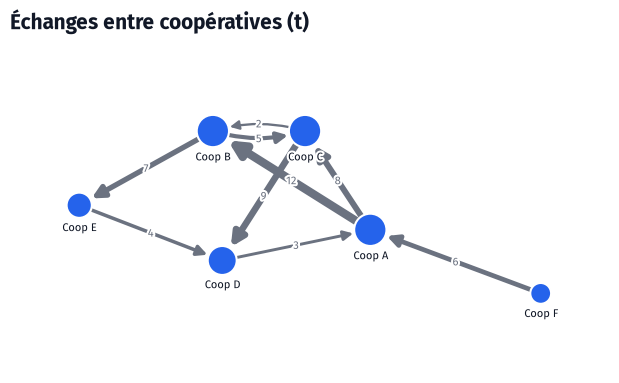

Coop A    4
Coop B    4
Coop C    4
Coop D    3
Coop E    2
Coop F    1
Name: degre, dtype: int64

In [2]:
echanges = pd.DataFrame([
    ('Coop A', 'Coop B', 12), ('Coop B', 'Coop C', 5), ('Coop A', 'Coop C', 8),
    ('Coop C', 'Coop D', 9), ('Coop D', 'Coop A', 3), ('Coop B', 'Coop E', 7),
    ('Coop E', 'Coop D', 4), ('Coop C', 'Coop B', 2), ('Coop F', 'Coop A', 6)],
    columns=['de', 'vers', 'tonnes'])
chart = (Chart(echanges)
    .network('de', 'vers', weight='tonnes', directed=True, edge_labels=True)
    .title('Échanges entre coopératives (t)')
    .tight_layout())
chart.show()
chart.graph['degree']

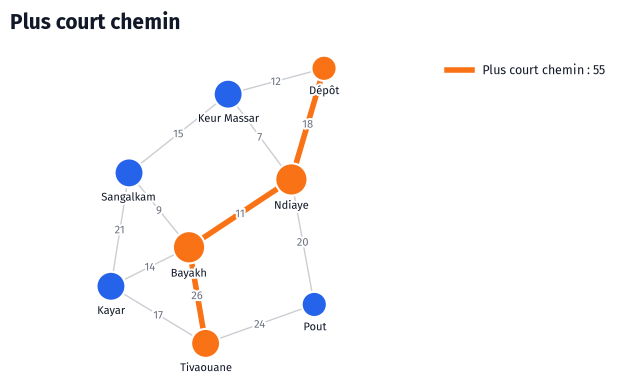

Dépôt → Ndiaye → Bayakh → Tivaouane | 55.0 km


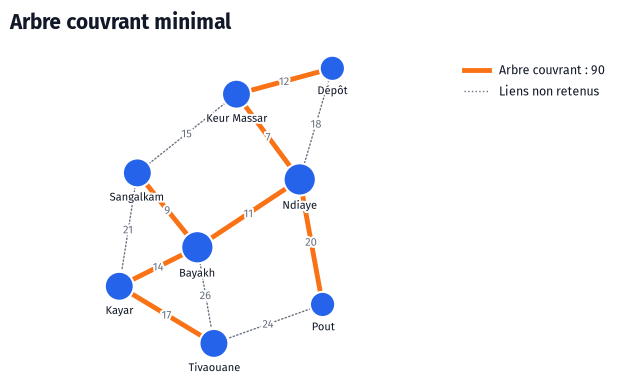

Longueur totale du réseau : 90.0 km


In [3]:
pistes = pd.DataFrame([
    ('Dépôt', 'Keur Massar', 12), ('Dépôt', 'Ndiaye', 18), ('Keur Massar', 'Ndiaye', 7),
    ('Keur Massar', 'Sangalkam', 15), ('Ndiaye', 'Bayakh', 11), ('Sangalkam', 'Bayakh', 9),
    ('Sangalkam', 'Kayar', 21), ('Bayakh', 'Kayar', 14), ('Bayakh', 'Tivaouane', 26),
    ('Kayar', 'Tivaouane', 17), ('Ndiaye', 'Pout', 20), ('Pout', 'Tivaouane', 24)],
    columns=['de', 'vers', 'km'])
chart = (Chart(pistes)
    .shortest_path('de', 'vers', 'Dépôt', 'Tivaouane', weight='km')
    .title('Plus court chemin')
    .tight_layout())
chart.show()
print(' → '.join(chart.path), '|', chart.path_length, 'km')

chart = Chart(pistes).spanning_tree('de', 'vers', weight='km')
chart.title('Arbre couvrant minimal').tight_layout().show()
print('Longueur totale du réseau :', chart.tree_weight, 'km')

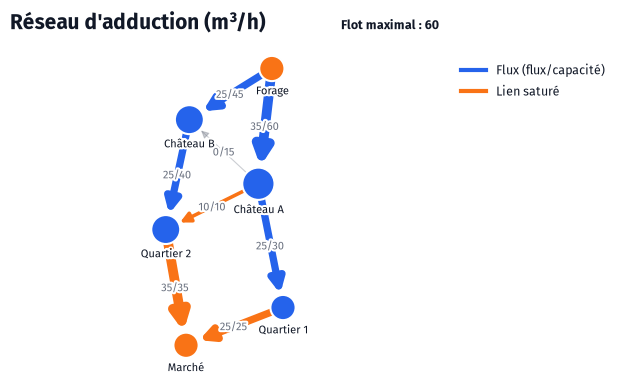

,de,vers,capacite,flux
0,Forage,Château A,60,35.0
1,Forage,Château B,45,25.0
2,Château A,Quartier 1,30,25.0
3,Château A,Château B,15,0.0
4,Château B,Quartier 2,40,25.0
5,Quartier 1,Marché,25,25.0
6,Quartier 2,Marché,35,35.0
7,Château A,Quartier 2,10,10.0


In [4]:
adduction = pd.DataFrame([
    ('Forage', 'Château A', 60), ('Forage', 'Château B', 45), ('Château A', 'Quartier 1', 30),
    ('Château A', 'Château B', 15), ('Château B', 'Quartier 2', 40), ('Quartier 1', 'Marché', 25),
    ('Quartier 2', 'Marché', 35), ('Château A', 'Quartier 2', 10)],
    columns=['de', 'vers', 'capacite'])
chart = Chart(adduction).max_flow('de', 'vers', 'capacite', 'Forage', 'Marché')
chart.title("Réseau d'adduction (m³/h)").tight_layout().show()
chart.flow

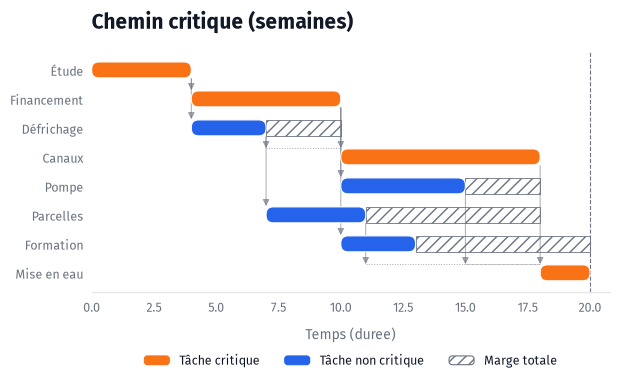

,duree,debut_tot,fin_tot,debut_tard,fin_tard,marge,critique
Étude,4.0,0.0,4.0,0.0,4.0,0.0,True
Financement,6.0,4.0,10.0,4.0,10.0,0.0,True
Défrichage,3.0,4.0,7.0,7.0,10.0,3.0,False
Canaux,8.0,10.0,18.0,10.0,18.0,0.0,True
Pompe,5.0,10.0,15.0,13.0,18.0,3.0,False
Parcelles,4.0,7.0,11.0,14.0,18.0,7.0,False
Formation,3.0,10.0,13.0,17.0,20.0,7.0,False
Mise en eau,2.0,18.0,20.0,18.0,20.0,0.0,True


In [5]:
projet = pd.DataFrame({
    'tache': ['Étude', 'Financement', 'Défrichage', 'Canaux', 'Pompe', 'Parcelles', 'Formation', 'Mise en eau'],
    'duree': [4, 6, 3, 8, 5, 4, 3, 2],
    'avant': ['', 'Étude', 'Étude', 'Défrichage, Financement', 'Financement', 'Défrichage',
              'Financement', 'Canaux, Pompe, Parcelles']})
chart = Chart(projet).critical_path('tache', 'duree', 'avant')
chart.title('Chemin critique (semaines)').tight_layout().show()
chart.schedule.drop(columns='predecesseurs')

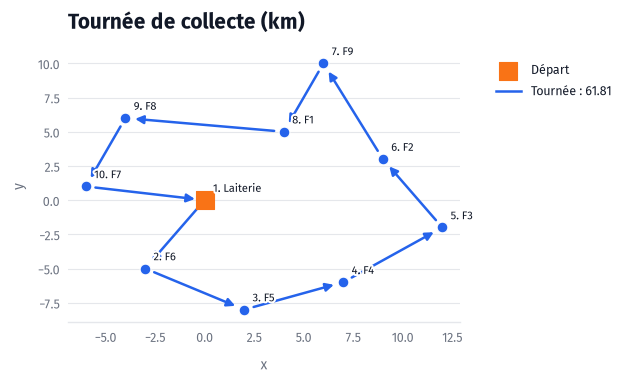

Laiterie → F6 → F5 → F4 → F3 → F2 → F9 → F1 → F8 → F7 | 61.8 km


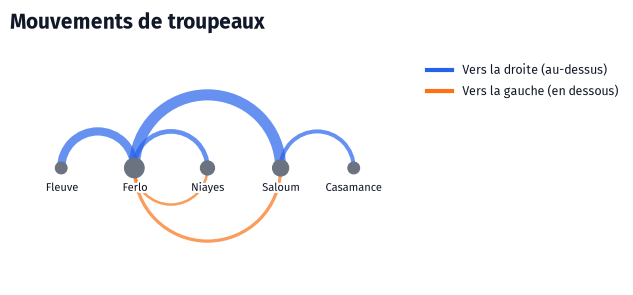

In [6]:
collecte = pd.DataFrame({
    'ferme': ['Laiterie', 'F1', 'F2', 'F3', 'F4', 'F5', 'F6', 'F7', 'F8', 'F9'],
    'x': [0, 4, 9, 12, 7, 2, -3, -6, -4, 6],
    'y': [0, 5, 3, -2, -6, -8, -5, 1, 6, 10]})
chart = Chart(collecte).tsp_route('x', 'y', labels='ferme', start='Laiterie')
chart.title('Tournée de collecte (km)').tight_layout().show()
print(' → '.join(chart.tour), '|', round(chart.tour_length, 1), 'km')

transferts = pd.DataFrame([
    ('Ferlo', 'Saloum', 420), ('Ferlo', 'Niayes', 150), ('Fleuve', 'Ferlo', 300),
    ('Saloum', 'Casamance', 120), ('Niayes', 'Ferlo', 60), ('Saloum', 'Ferlo', 90)],
    columns=['depart', 'arrivee', 'tetes'])
(Chart(transferts)
    .arc_diagram('depart', 'arrivee', weight='tetes',
                 order=['Fleuve', 'Ferlo', 'Niayes', 'Saloum', 'Casamance'])
    .title('Mouvements de troupeaux')
    .tight_layout()
    .show())